<a href="https://colab.research.google.com/github/nirmitashah29-creator/NirmitaShah_LP_Synapse26/blob/project/fraud_detection_complete_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import zipfile

zip_path = '/content/drive/MyDrive/creditcard.csv.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/')

In [8]:
import pandas as pd

df = pd.read_csv('/content/creditcard.csv')
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [9]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [10]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [11]:
df.duplicated().sum()

np.int64(1081)

In [12]:
df['Class'].value_counts()

,count
Class,
0,284315
1,492


In [13]:
df['Class'].value_counts(normalize=True) * 100

,proportion
Class,
0,99.827251
1,0.172749


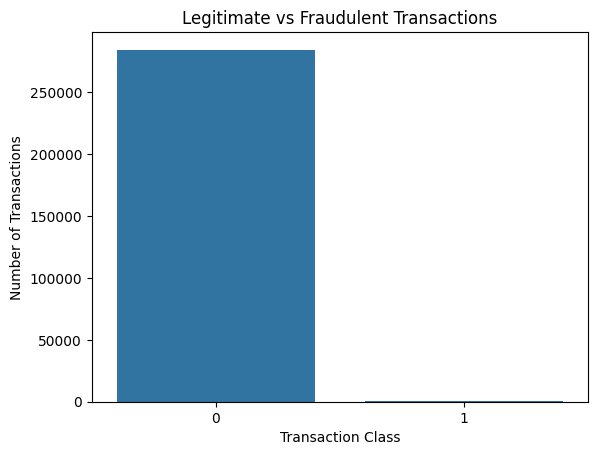

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x='Class', data=df)
plt.title('Legitimate vs Fraudulent Transactions')
plt.xlabel('Transaction Class')
plt.ylabel('Number of Transactions')
plt.show()

In [15]:
duplicates = df[df.duplicated()]
duplicates.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0


In [16]:
df[df.duplicated()]['Class'].value_counts()

,count
Class,
0,1062
1,19


In [17]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [18]:
df.shape


(283726, 31)

In [19]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,...,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000
mean,94811.077600,0.005917,-0.004135,0.001613,-0.002966,0.001828,-0.001139,0.001801,-0.000854,-0.001596,...,-0.000371,-0.000015,0.000198,0.000214,-0.000232,0.000149,0.001763,0.000547,88.472687,0.001667
std,47481.047891,1.948026,1.646703,1.508682,1.414184,1.377008,1.331931,1.227664,1.179054,1.095492,...,0.723909,0.724550,0.623702,0.605627,0.521220,0.482053,0.395744,0.328027,250.399437,0.040796
min,0.000000,-56.407510,-72.715728,-48.325589,-5.683171,-113.743307,-26.160506,-43.557242,-73.216718,-13.434066,...,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-15.430084,0.000000,0.000000
25%,54204.750000,-0.915951,-0.600321,-0.889682,-0.850134,-0.689830,-0.769031,-0.552509,-0.208828,-0.644221,...,-0.228305,-0.542700,-0.161703,-0.354453,-0.317485,-0.326763,-0.070641,-0.052818,5.600000,0.000000
50%,84692.500000,0.020384,0.063949,0.179963,-0.022248,-0.053468,-0.275168,0.040859,0.021898,-0.052596,...,-0.029441,0.006675,-0.011159,0.041016,0.016278,-0.052172,0.001479,0.011288,22.000000,0.000000
75%,139298.000000,1.316068,0.800283,1.026960,0.739647,0.612218,0.396792,0.570474,0.325704,0.595977,...,0.186194,0.528245,0.147748,0.439738,0.350667,0.240261,0.091208,0.078276,77.510000,0.000000
max,172792.000000,2.454930,22.057729,9.382558,16.875344,34.801666,73.301626,120.589494,20.007208,15.594995,...,27.202839,10.503090,22.528412,4.584549,7.519589,3.517346,31.612198,33.847808,25691.160000,1.000000


In [20]:
df.groupby('Class')['Amount'].mean()

,Amount
Class,
0,88.413575
1,123.871860


In [21]:
df.groupby('Class')['Amount'].median()

,Amount
Class,
0,22.00
1,9.82


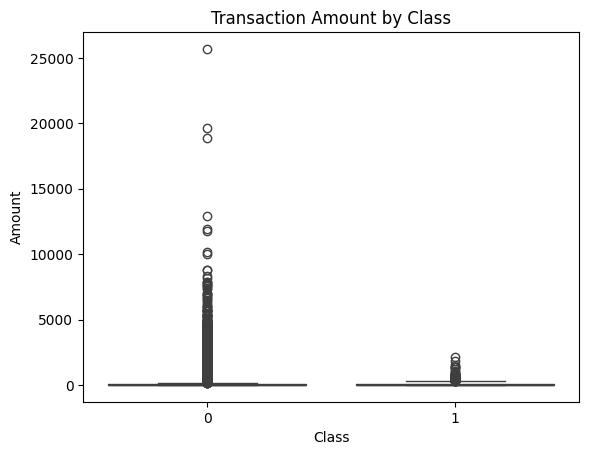

In [22]:
sns.boxplot(x='Class', y='Amount', data=df)
plt.title('Transaction Amount by Class')
plt.show()

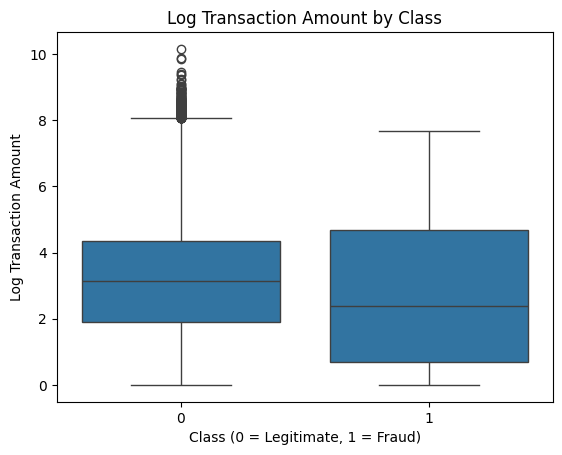

In [23]:
import numpy as np
df['Log_Amount'] = np.log1p(df['Amount'])

sns.boxplot(x='Class', y='Log_Amount', data=df)
plt.title('Log Transaction Amount by Class')
plt.xlabel('Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Log Transaction Amount')
plt.show()

# Phase 2: Data preprocessing

In [24]:
!pip -q install imbalanced-learn xgboost
import numpy as np, time
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
X = df.drop(columns=['Class', 'Amount'])
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),      columns=X.columns, index=X_test.index)

smote = SMOTE(sampling_strategy=0.1, random_state=42)
X_res, y_res = smote.fit_resample(X_train_s, y_train)

print('Train before:', y_train.value_counts().to_dict())
print('Train after SMOTE:', y_res.value_counts().to_dict())
print('Test (untouched):', y_test.value_counts().to_dict())

Train before: {0: 226602, 1: 378}
Train after SMOTE: {0: 226602, 1: 22660}
Test (untouched): {0: 56651, 1: 95}


In [29]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import recall_score, precision_score, f1_score

for depth in [3, 5, 8, 10, 15, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_res, y_res)
    pred = model.predict(X_test_s)

    print(
        f"Depth: {depth} | "
        f"Precision: {precision_score(y_test, pred):.4f} | "
        f"Recall: {recall_score(y_test, pred):.4f} | "
        f"F1: {f1_score(y_test, pred):.4f}"
    )

Depth: 3 | Precision: 0.5396 | Recall: 0.7895 | F1: 0.6410
Depth: 5 | Precision: 0.5814 | Recall: 0.7895 | F1: 0.6696
Depth: 8 | Precision: 0.3889 | Recall: 0.7368 | F1: 0.5091
Depth: 10 | Precision: 0.2792 | Recall: 0.7053 | F1: 0.4000
Depth: 15 | Precision: 0.3812 | Recall: 0.7263 | F1: 0.5000
Depth: None | Precision: 0.3710 | Recall: 0.7263 | F1: 0.4911


In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

for iterations in [100, 500, 1000, 2000]:
    model = LogisticRegression(max_iter=iterations, random_state=42)
    model.fit(X_res, y_res)
    pred = model.predict(X_test_s)

    print(
        f"Iterations: {iterations} | "
        f"Precision: {precision_score(y_test, pred):.4f} | "
        f"Recall: {recall_score(y_test, pred):.4f} | "
        f"F1: {f1_score(y_test, pred):.4f}"
    )

Iterations: 100 | Precision: 0.4031 | Recall: 0.8105 | F1: 0.5385
Iterations: 500 | Precision: 0.4031 | Recall: 0.8105 | F1: 0.5385
Iterations: 1000 | Precision: 0.4031 | Recall: 0.8105 | F1: 0.5385
Iterations: 2000 | Precision: 0.4031 | Recall: 0.8105 | F1: 0.5385


In [27]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import precision_score, recall_score, f1_score

model = GaussianNB()
model.fit(X_res, y_res)

pred = model.predict(X_test_s)

print("Precision:", precision_score(y_test, pred))
print("Recall:", recall_score(y_test, pred))
print("F1-score:", f1_score(y_test, pred))

Precision: 0.05392156862745098
Recall: 0.8105263157894737
F1-score: 0.10111621799080761


In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

for trees in [20, 50, 100]:
    model = RandomForestClassifier(
        n_estimators=trees,
        max_depth=8,
        n_jobs=-1,
        random_state=42
    )

    model.fit(X_res, y_res)
    pred = model.predict(X_test_s)

    print(
        f"Trees: {trees} | "
        f"Precision: {precision_score(y_test, pred):.4f} | "
        f"Recall: {recall_score(y_test, pred):.4f} | "
        f"F1: {f1_score(y_test, pred):.4f}"
    )

Trees: 20 | Precision: 0.8090 | Recall: 0.7579 | F1: 0.7826
Trees: 50 | Precision: 0.8471 | Recall: 0.7579 | F1: 0.8000
Trees: 100 | Precision: 0.8571 | Recall: 0.7579 | F1: 0.8045


In [31]:
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

for depth in [3, 5, 7]:
    model = XGBClassifier(
        n_estimators=100,
        max_depth=depth,
        learning_rate=0.1,
        eval_metric='aucpr',
        n_jobs=-1,
        random_state=42
    )

    model.fit(X_res, y_res)
    pred = model.predict(X_test_s)

    print(
        f"Depth: {depth} | "
        f"Precision: {precision_score(y_test, pred):.4f} | "
        f"Recall: {recall_score(y_test, pred):.4f} | "
        f"F1: {f1_score(y_test, pred):.4f}"
    )

Depth: 3 | Precision: 0.6417 | Recall: 0.8105 | F1: 0.7163
Depth: 5 | Precision: 0.7184 | Recall: 0.7789 | F1: 0.7475
Depth: 7 | Precision: 0.8065 | Recall: 0.7895 | F1: 0.7979


In [32]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

for estimators in [25, 50, 100, 150]:
    model = AdaBoostClassifier(
        n_estimators=estimators,
        random_state=42
    )

    model.fit(X_res, y_res)
    pred = model.predict(X_test_s)

    print(
        f"Estimators: {estimators} | "
        f"Precision: {precision_score(y_test, pred):.4f} | "
        f"Recall: {recall_score(y_test, pred):.4f} | "
        f"F1: {f1_score(y_test, pred):.4f}"
    )

Estimators: 25 | Precision: 0.3817 | Recall: 0.7474 | F1: 0.5053
Estimators: 50 | Precision: 0.4148 | Recall: 0.7684 | F1: 0.5387
Estimators: 100 | Precision: 0.3886 | Recall: 0.7895 | F1: 0.5208
Estimators: 150 | Precision: 0.4000 | Recall: 0.8000 | F1: 0.5333


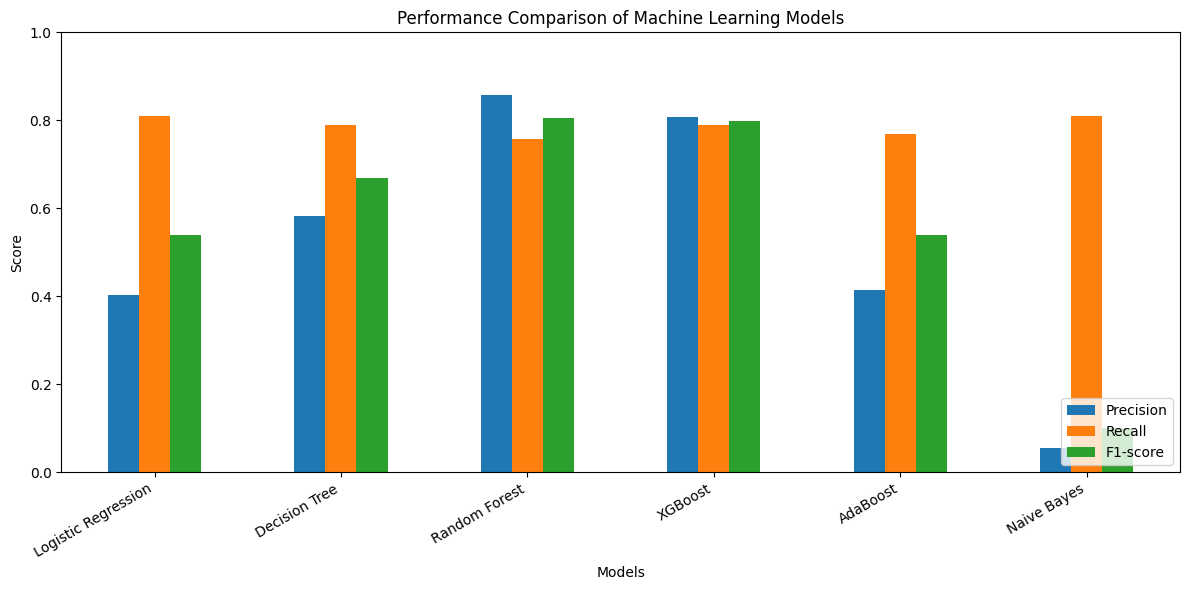

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

results = {
    'Logistic Regression': [0.4031, 0.8105, 0.5385],
    'Decision Tree': [0.5814, 0.7895, 0.6696],
    'Random Forest': [0.8571, 0.7579, 0.8045],
    'XGBoost': [0.8065, 0.7895, 0.7979],
    'AdaBoost': [0.4148, 0.7684, 0.5387],
    'Naive Bayes': [0.0539, 0.8105, 0.1011]
}

comparison = pd.DataFrame(
    results,
    index=['Precision', 'Recall', 'F1-score']
).T

comparison.plot(kind='bar', figsize=(12, 6))

plt.title('Performance Comparison of Machine Learning Models')
plt.ylabel('Score')
plt.xlabel('Models')
plt.ylim(0, 1)
plt.xticks(rotation=30, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [13]:

probas = {}
predictions = {}

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=8, n_jobs=-1, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=100, max_depth=7, learning_rate=0.1, eval_metric='aucpr', n_jobs=-1, random_state=42),
    'AdaBoost': AdaBoostClassifier(n_estimators=50, random_state=42),
    'Naive Bayes': GaussianNB()
}

for name, model in models.items():
    model.fit(X_res, y_res)
    probas[name] = model.predict_proba(X_test_s)[:, 1]
    predictions[name] = (probas[name] >= 0.5).astype(int)


In [11]:
import os
os.listdir('/content')

['.config', 'drive', 'creditcard.csv', 'sample_data']

In [12]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

df = pd.read_csv('/content/creditcard.csv')

df = df.drop_duplicates()

df['Log_Amount'] = np.log1p(df['Amount'])

X = df.drop(columns=['Class', 'Amount'])
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

smote = SMOTE(sampling_strategy=0.1, random_state=42)

X_res, y_res = smote.fit_resample(X_train_s, y_train)

print(X_res.shape)
print(y_res.shape)
print(X_test_s.shape)
print(y_test.shape)

(249262, 30)
(249262,)
(56746, 30)
(56746,)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    roc_curve, precision_recall_curve,
    roc_auc_score, average_precision_score
)
from xgboost import XGBClassifier

In [38]:
print(probas.keys())

dict_keys(['Logistic Regression', 'Decision Tree'])


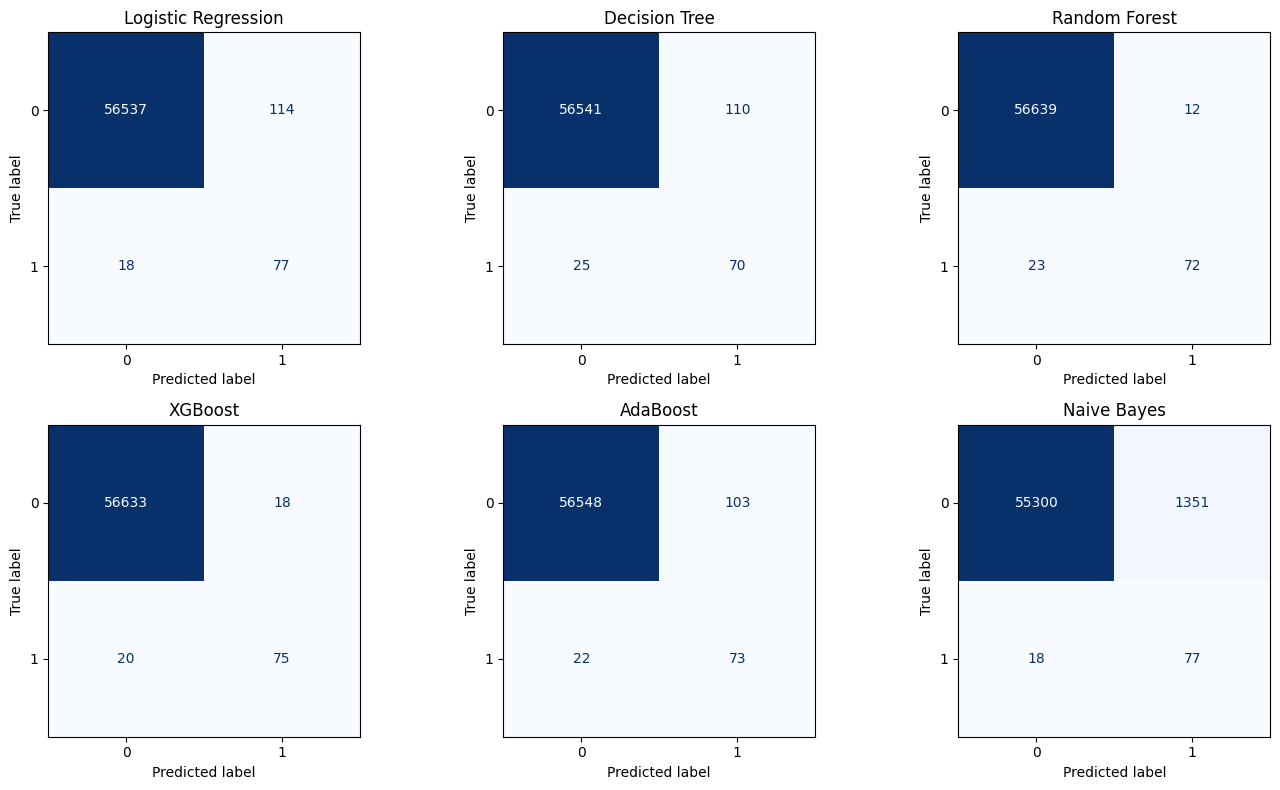

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(
        ax=ax, cmap='Blues', colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

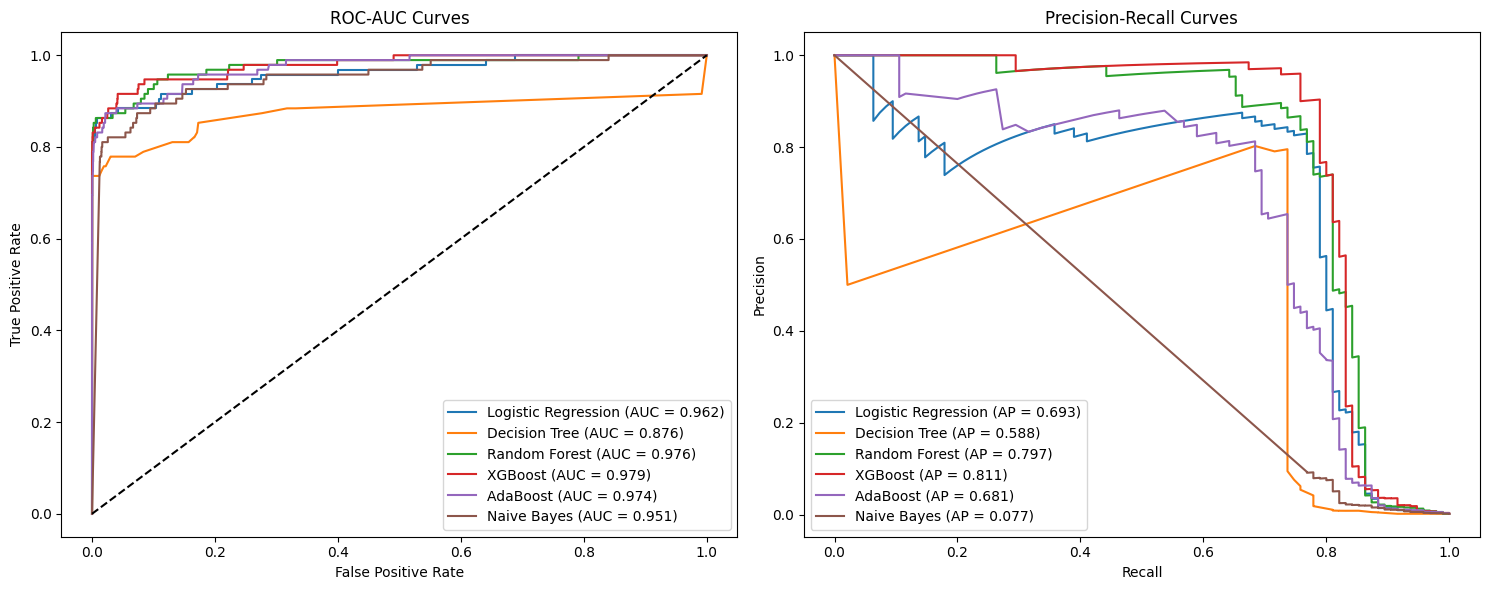

In [14]:
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

fig, ax = plt.subplots(1, 2, figsize=(15, 6))

for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    roc_auc = roc_auc_score(y_test, p)
    ax[0].plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')

    precision, recall, _ = precision_recall_curve(y_test, p)
    pr_auc = average_precision_score(y_test, p)
    ax[1].plot(recall, precision, label=f'{name} (AP = {pr_auc:.3f})')

ax[0].plot([0, 1], [0, 1], 'k--')
ax[0].set_title('ROC-AUC Curves')
ax[0].set_xlabel('False Positive Rate')
ax[0].set_ylabel('True Positive Rate')
ax[0].legend()

ax[1].set_title('Precision-Recall Curves')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].legend()

plt.tight_layout()
plt.show()

In [49]:
##FOR RUNTIME
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'Naive Bayes': GaussianNB(),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'XGBoost': XGBClassifier(eval_metric='aucpr', random_state=42, n_jobs=-1)
}

In [51]:
#PRAUC
from sklearn.metrics import average_precision_score

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    n_jobs=-1,
    random_state=42
)

rf.fit(X_res, y_res)
rf_probs = rf.predict_proba(X_test_s)[:, 1]

xgb = XGBClassifier(
    n_estimators=100,
    max_depth=7,
    learning_rate=0.1,
    eval_metric='aucpr',
    n_jobs=-1,
    random_state=42
)

xgb.fit(X_res, y_res)
xgb_probs = xgb.predict_proba(X_test_s)[:, 1]

print("Random Forest PR-AUC:", average_precision_score(y_test, rf_probs))
print("XGBoost PR-AUC:", average_precision_score(y_test, xgb_probs))

Random Forest PR-AUC: 0.7966717920172218
XGBoost PR-AUC: 0.8114077949628107


In [52]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, loguniform

param_dists = {
    'Random Forest': {
        'clf__n_estimators': randint(50, 101),
        'clf__max_depth': randint(5, 12),
        'clf__min_samples_leaf': randint(1, 5)
    },
    'XGBoost': {
        'clf__n_estimators': randint(50, 101),
        'clf__max_depth': randint(3, 7),
        'clf__learning_rate': loguniform(0.03, 0.2)
    }
}

models_to_tune = {
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(eval_metric='aucpr', random_state=42, n_jobs=-1)
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

tuned = {}

for name, model in models_to_tune.items():
    pipe = ImbPipeline([
        ('smote', SMOTE(sampling_strategy=0.1, random_state=42)),
        ('clf', model)
    ])

    search = RandomizedSearchCV(
        pipe,
        param_dists[name],
        n_iter=2,
        scoring='average_precision',
        cv=cv,
        n_jobs=1,
        random_state=42,
        verbose=1
    )

    search.fit(X_train_s, y_train)
    tuned[name] = search

    print(name)
    print("Best PR-AUC:", search.best_score_)
    print("Best parameters:", search.best_params_)

Fitting 3 folds for each of 2 candidates, totalling 6 fits
Random Forest
Best PR-AUC: 0.8394776610950343
Best parameters: {'clf__max_depth': 11, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 57}
Fitting 3 folds for each of 2 candidates, totalling 6 fits
XGBoost
Best PR-AUC: 0.811780663838111
Best parameters: {'clf__learning_rate': np.float64(0.12028665880905137), 'clf__max_depth': 3, 'clf__n_estimators': 70}


In [ ]:
tuned_predictions = {}

for name, search in tuned.items():
    model = search.best_estimator_
    tuned_predictions[name] = model.predict(X_test_s)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, pred) in zip(axes.ravel(), tuned_predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(
        ax=ax, cmap='Blues', colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()


dict_keys(['Random Forest (tuned)', 'XGBoost (tuned)'])
Best tuned model: Random Forest (tuned)
F1-optimal threshold (from train OOF): 0.735


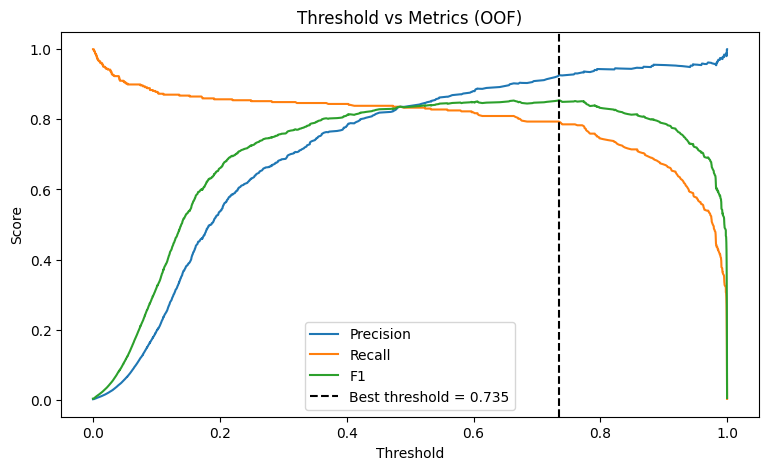

In [58]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import average_precision_score, precision_recall_curve
import numpy as np
import matplotlib.pyplot as plt

tuned_probas = {}

for name, s in tuned.items():
    p = s.best_estimator_.predict_proba(X_test_s)[:, 1]
    tuned_probas[name + ' (tuned)'] = p

print(tuned_probas.keys())

best_name = max(
    tuned_probas,
    key=lambda k: average_precision_score(y_test, tuned_probas[k])
)

base = best_name.replace(' (tuned)', '')
best_pipe = tuned[base].best_estimator_

print('Best tuned model:', best_name)

oof = cross_val_predict(
    best_pipe,
    X_train_s,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)

f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)

best_t = thr[np.argmax(f1s)]

print(f'F1-optimal threshold (from train OOF): {best_t:.3f}')

plt.figure(figsize=(9, 5))
plt.plot(thr, prec[:-1], label='Precision')
plt.plot(thr, rec[:-1], label='Recall')
plt.plot(thr, f1s, label='F1')
plt.axvline(best_t, color='black', linestyle='--', label=f'Best threshold = {best_t:.3f}')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.title('Threshold vs Metrics (OOF)')
plt.show()

,Precision,Recall,F1,PR-AUC,ROC-AUC
Random Forest (tuned) @ t=0.73,0.9452,0.7263,0.8214,0.8093,0.9800
Random Forest (tuned) @ t=0.5,0.8765,0.7474,0.8068,0.8093,0.9800
"Logistic Regression (default, t=0.5)",0.4031,0.8105,0.5385,0.6928,0.9621
"Decision Tree (default, t=0.5)",0.3889,0.7368,0.5091,0.5878,0.8762


              precision    recall  f1-score   support

       Legit     0.9995    0.9999    0.9997     56651
       Fraud     0.9452    0.7263    0.8214        95

    accuracy                         0.9995     56746
   macro avg     0.9724    0.8631    0.9106     56746
weighted avg     0.9995    0.9995    0.9994     56746



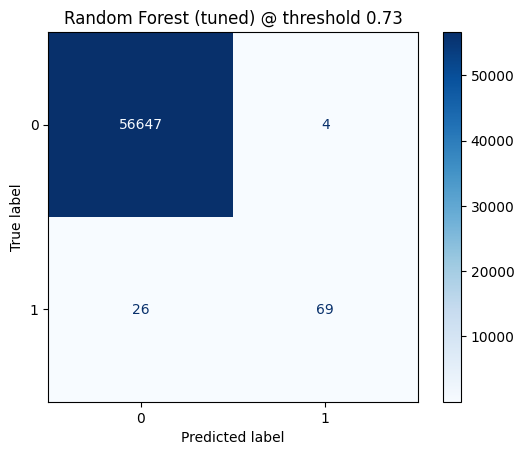

In [62]:
p_best = tuned_probas[best_name]
final = {name + ' (default, t=0.5)': metrics(y_test, probas[name]) for name in probas}
final[best_name + ' @ t=0.5']        = metrics(y_test, p_best, 0.5)
final[best_name + f' @ t={best_t:.2f}'] = metrics(y_test, p_best, best_t)
final_df = pd.DataFrame(final).T.sort_values(['F1'], ascending=False).round(4)
display(final_df)

pred_final = (p_best >= best_t).astype(int)
print(classification_report(y_test, pred_final, target_names=['Legit', 'Fraud'], digits=4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_final)).plot(cmap='Blues')
plt.title(f'{best_name} @ threshold {best_t:.2f}'); plt.show()

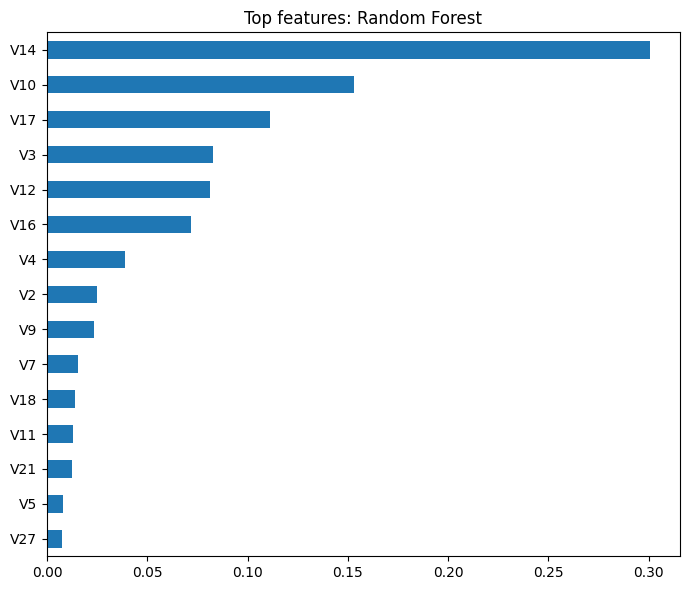

In [63]:

clf = best_pipe.named_steps['clf']
if hasattr(clf, 'feature_importances_'):
    imp = pd.Series(clf.feature_importances_, index=X.columns).sort_values().tail(15)
elif hasattr(clf, 'coef_'):
    imp = pd.Series(np.abs(clf.coef_[0]), index=X.columns).sort_values().tail(15)
else:
    imp = None
if imp is not None:
    imp.plot(kind='barh', figsize=(7, 6)); plt.title(f'Top features: {base}'); plt.tight_layout(); plt.show()

Project Conclusion
- Built a machine learning model to detect fraudulent credit card transactions.
- Cleaned and preprocessed the dataset by removing duplicates and scaling features.
- Used SMOTE to handle class imbalance.
- Trained and compared six classification algorithms.
- Evaluated models using Precision, Recall, F1-score, ROC-AUC, and PR-AUC.
- Applied hyperparameter tuning to improve Random Forest and XGBoost.
- Used threshold tuning to balance precision and recall.
- Performed feature importance analysis to identify the most influential features.
- Demonstrated how machine learning can help detect fraud and reduce potential financial losses.
-Selected Tuned Random Forest as the final model.
-Achieved 94.52% Precision, meaning most transactions flagged as fraud were actually fraudulent.
-Achieved 72.63% Recall, meaning the model detected approximately 73% of actual fraudulent transactions.
-Achieved an 82.14% F1-score.
-Obtained 0.8093 PR-AUC and 0.9800 ROC-AUC.
-Threshold tuning improved precision from 87.65% to 94.52%, with a small decrease in recall.